In [64]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch.nn.utils as utils
import torchvision.utils as vutils
import numpy as np
from torch.utils.data import DataLoader, Dataset
import cv2
import os
import seaborn as sns    
import gc
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

**Data**

In [65]:
def clear_cuda():

    # 1. Удаляем ненужные переменные (модели, тензоры, лоссы и т.д.)
    # del my_model, my_tensor, loss
    
    # 2. Запускаем сборщик мусора Python (разрывает циклические ссылки)
    gc.collect()
    
    # 3. Очищаем кэш CUDA (возвращает свободную кэшированную память в ОС)
    torch.cuda.empty_cache()

In [66]:
clear_cuda()

In [67]:
image_dir = '/kaggle/input/datasets/nunenuh/pytorch-challange-flower-dataset/dataset/train/'

In [68]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    # transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, .5, .5]),
])


class Flower102(Dataset):
    def __init__(self, transform=None):
        image_paths = [list(map(lambda name: class_name + '/' + name, os.listdir(image_dir + class_name))) for class_name in os.listdir(image_dir)]
        image_paths = sum(image_paths, [])
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = os.path.join(image_dir, self.image_paths[idx])
        img = Image.open(img_path).convert('RGB')
        return self.transform(img)

dataset = Flower102(transform=transform)

data_loader = DataLoader(dataset, batch_size=128, shuffle=True, pin_memory=True, drop_last=True)

**Architechture**

In [69]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [70]:
def ConvBlock(in_channels, out_channels, kernel_size=3, stride=1, padding=1, dropout=.1):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding),
        nn.GELU(),
        nn.BatchNorm2d(out_channels),
        nn.Conv2d(out_channels, out_channels, 1),
        nn.GELU(),
        nn.Dropout2d(dropout),
        nn.BatchNorm2d(out_channels)
    )


def LinearBlock(in_channels, out_channels):
    return nn.Sequential(
        nn.Linear(in_channels, out_channels),
        nn.LeakyReLU(),
        nn.Linear(out_channels, in_channels),
        nn.LeakyReLU(),
        nn.Linear(in_channels, out_channels),
        nn.BatchNorm1d(out_channels)
    )

In [71]:
class Encoder(nn.Module):
    def __init__(self, w_dim, X, codebook_size):
        super().__init__()
        self.X = X
        self.codebook_size = codebook_size
        self.w_dim = w_dim

        self.pool = nn.MaxPool2d(2)
        self.c1 = ConvBlock(3, 64 * w_dim)
        self.c2 = ConvBlock(64 * w_dim, 128 * w_dim)
        self.c3 = ConvBlock(128 * w_dim, 256 * w_dim)
        self.c4 = ConvBlock(256 * w_dim, 512 * w_dim)
        self.c5 = ConvBlock(512 * w_dim, 256 * w_dim)

        self.lin_mu = LinearBlock(256 * w_dim, codebook_size)
        self.lin_logvar = LinearBlock(256 * w_dim, codebook_size)
    
    def forward(self, x, tau):
        x = self.c1(x)
        x = self.pool(x)
        x = self.c2(x)
        x = self.pool(x)
        x = self.c3(x)
        x = self.pool(x)
        x = self.c4(x)
        x = self.pool(x)
        x = self.c5(x) # ( N, 256*w_dim, H, W )

        x = torch.flatten(x, start_dim=-2) # ( N, 256*w_dim, H*W )
        x = x.permute(0, 2, 1) # ( N, H*W, 256*w_dim )
        x = x.reshape(-1, 256 * self.w_dim)

        mu_logits = self.lin_mu(x).view(-1, self.X * self.X, self.codebook_size)
        logvar_logits = self.lin_logvar(x).view(-1, self.X * self.X, self.codebook_size)

        mu_probs = F.gumbel_softmax(mu_logits, tau=tau, hard=False)
        logvar_probs = F.gumbel_softmax(logvar_logits, tau=tau, hard=False)
        
        return mu_probs, logvar_probs

In [72]:
class Codebook(nn.Module):
    def __init__(self, codebook_size, hidden_dim):
        super().__init__()

        self.mu_embed = nn.Parameter(torch.randn(codebook_size, hidden_dim))
        self.logvar_embed = nn.Parameter(torch.randn(codebook_size, hidden_dim))

        # self.lin ???

    def forward(self, mu_probs, logvar_probs):
        mu = torch.matmul(mu_probs, self.mu_embed)
        logvar = torch.matmul(mu_probs, self.mu_embed)

        return mu, logvar

In [73]:
class Decoder(nn.Module):
    def __init__(self, w_dim, hidden_dim, X):
        super().__init__()

        self.w_dim = w_dim
        self.X = X
        self.hidden_dim = hidden_dim

        self.upsample = nn.PixelShuffle(upscale_factor=2)

        self.lin = LinearBlock(hidden_dim, hidden_dim)

        self.c1 = ConvBlock(hidden_dim, 256 * w_dim)
        self.c2 = ConvBlock(64 * w_dim, 256 * w_dim)
        self.c3 = ConvBlock(64 * w_dim, 256 * w_dim)
        self.c4 = ConvBlock(64 * w_dim, 256 * w_dim)
        self.c5 = ConvBlock(64 * w_dim, 3)
        self.out = nn.Sigmoid()

    def reparametrization(self, mu, logvar):
        noise = torch.randn(self.hidden_dim, device=device)
        return noise * torch.exp(logvar) + mu

    def forward(self, mu, logvar):
        x = self.reparametrization(mu, logvar) # ( N, X*X, hidden_dim )
        x = x.view(-1, self.hidden_dim) # ( N*X*X, hidden_dim )
        x = self.lin(x)
        
        x = x.view(-1, self.hidden_dim, self.X, self.X) # (N, hidden_dim, X, X)
        
        x = self.c1(x)
        x = self.upsample(x)
        x = self.c2(x)
        x = self.upsample(x)
        x = self.c3(x)
        x = self.upsample(x)
        x = self.c4(x)
        x = self.upsample(x)
        x = self.c5(x)
        x = self.out(x)
        return x


In [74]:
class AE(nn.Module):
    def __init__(self, enc, dec, cod):
        super().__init__()
        self.enc = enc
        self.dec = dec
        self.cod = cod
    
    def generate(self, mu, logvar):
        return self.dec(mu, logvar)
    
    def forward(self, x):
        pass

**Models definition**

In [75]:
# Параметры

w_dim = 2
hidden_dim = 128

X, Y = 4, 128

encoder = Encoder(w_dim, X, Y)
decoder = Decoder(w_dim, hidden_dim, X)
codebook = Codebook(Y, hidden_dim)

ae = AE(encoder, decoder, codebook).to(device)

optimizer = optim.AdamW(ae.parameters(), lr=3e-4)


**Image Generation / Presentation**

In [76]:
def generate_images(ae, n_images=4):
    with torch.no_grad():
        mu = torch.zeros(n_images, X * X, hidden_dim, device=device, requires_grad=False)
        logvar = torch.zeros(n_images, X * X, hidden_dim, device=device, requires_grad=False)
        images = ae.generate(mu, logvar).detach().cpu()
    return images

In [77]:
def show_images(ae, title, n_images=4):
    images = generate_images(ae, n_images)
    # make_grid сам соберет картинки в одну строку (nrow=len(images))
    # normalize=True сам переведет из диапазона сети в [0, 1]
    grid = vutils.make_grid(images.detach().cpu(), nrow=len(images), padding=2, normalize=True)

    plt.figure(figsize=(len(images) * 2, 3))
    plt.axis("off")
    plt.title(f"epoch №{title}")

    # make_grid возвращает (C, H, W), поэтому всё равно нужно permute для imshow
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.show()

In [78]:
def show_rec_images(ae, title, n_images=4):
    for batch_id, data in enumerate(data_loader):
        imgs = data.to(device, non_blocking=True)

        mu_probs, logvar_probs = ae.enc(imgs, tau=1)
        mu, logvar = ae.cod(mu_probs, logvar_probs)
        rec_imgs = ae.dec(mu, logvar)
        break
    # make_grid сам соберет картинки в одну строку (nrow=len(images))
    # normalize=True сам переведет из диапазона сети в [0, 1]
    imgs = imgs[:n_images]
    rec_imgs = rec_imgs[:n_images]
    real_grid = vutils.make_grid(imgs.detach().cpu(), nrow=n_images, padding=2, normalize=True)
    rec_grid = vutils.make_grid(rec_imgs.detach().cpu(), nrow=n_images, padding=2, normalize=True)
    grid = vutils.make_grid([real_grid, rec_grid], nrow=2, padding=0, normalize=True)

    plt.figure(figsize=(n_images * 4, 3))
    plt.axis("off")
    plt.title(f"epoch №{title}")

    # make_grid возвращает (C, H, W), поэтому всё равно нужно permute для imshow
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.show()

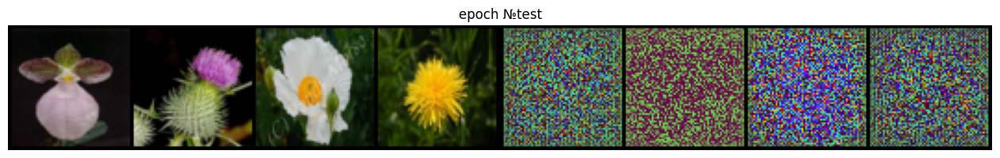

In [79]:
show_rec_images(ae, 'test')

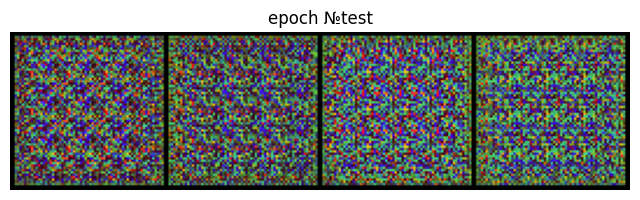

In [80]:
show_images(ae, "test")

**Training Loop**

In [81]:
criterion = nn.MSELoss()
n_epochs = 100


def beta(epoch, max_epochs, max_weight=1.0):
    return max_weight * min(1.0, epoch / (max_epochs * 0.5))

def tau(epoch, max_epoch, start, end):
    return start * (end / start) ** (epoch / max_epoch)

def kl_loss(logvar, mu):
    return -.5 * torch.mean(1 + logvar - mu * mu - logvar.exp())

def rec_loss(imgs, rec_imgs):
    return criterion(rec_imgs, imgs)

def usage_loss(probs):
    return probs.mean(dim=(0, 1)).std()

def loss_fn(imgs, rec_imgs, mu, logvar, epoch, mu_probs, logvar_probs):
    return rec_loss(imgs, rec_imgs) + beta(epoch, n_epochs) * kl_loss(logvar, mu) + beta(epoch, n_epochs, max_weight=0.5) * (usage_loss(mu_probs) + usage_loss(logvar_probs))

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[0/100], Loss: 0.092


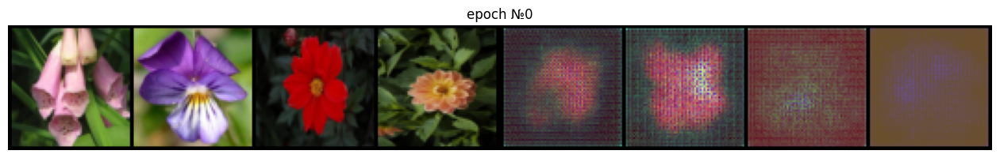

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[1/100], Loss: 0.079


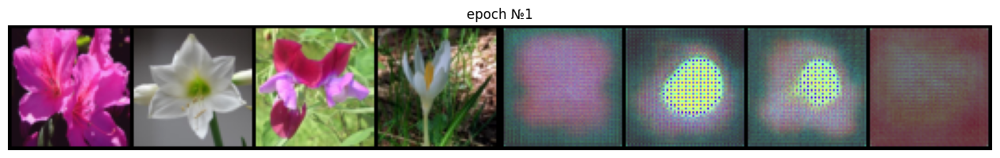

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[2/100], Loss: 0.076


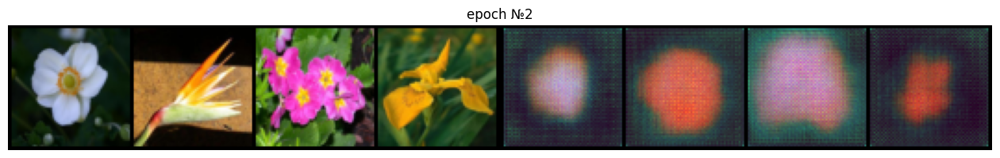

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[3/100], Loss: 0.075


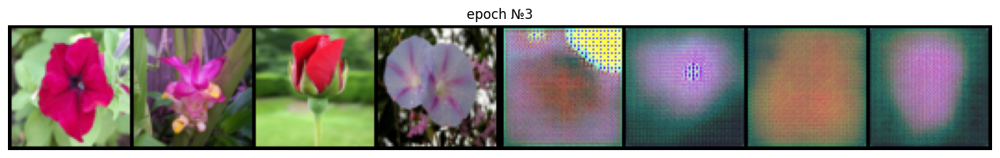

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[4/100], Loss: 0.074


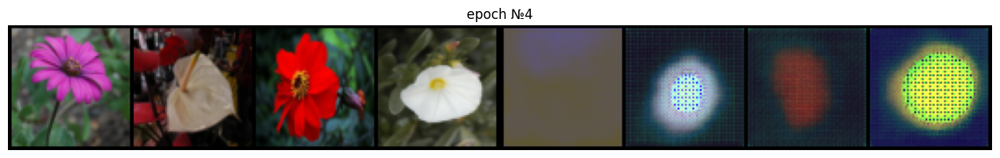

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[5/100], Loss: 0.076


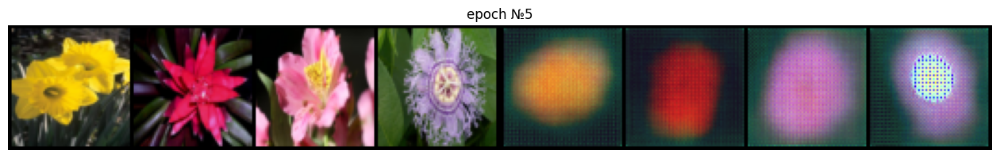

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[6/100], Loss: 0.077


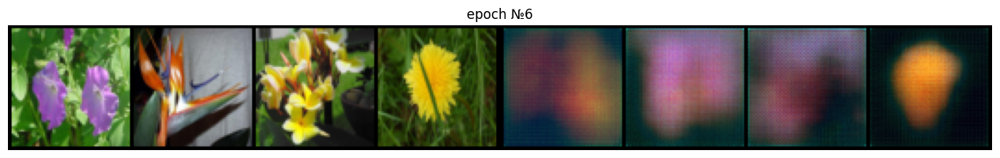

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[7/100], Loss: 0.079


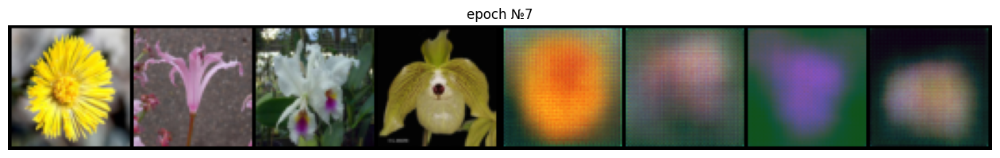

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[8/100], Loss: 0.081


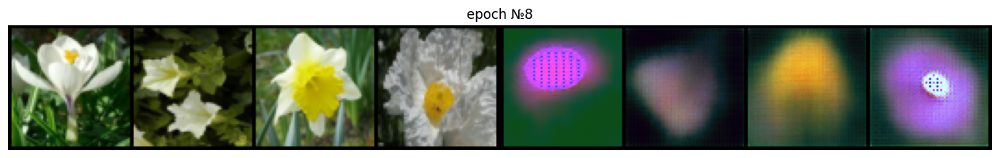

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[9/100], Loss: 0.083


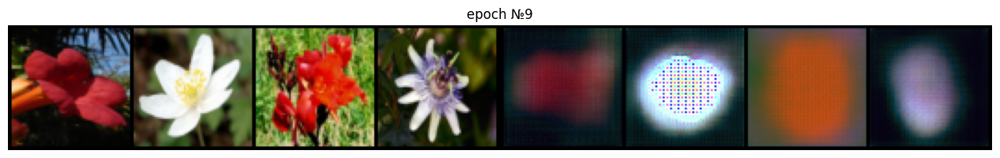

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[10/100], Loss: 0.086


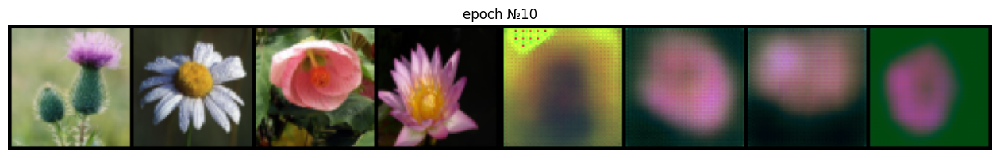

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[11/100], Loss: 0.089


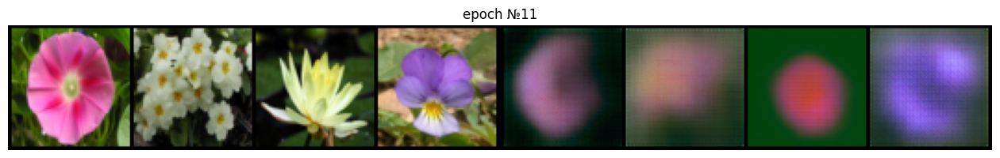

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[12/100], Loss: 0.092


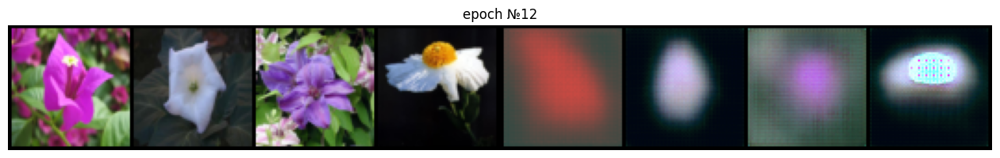

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[13/100], Loss: 0.095


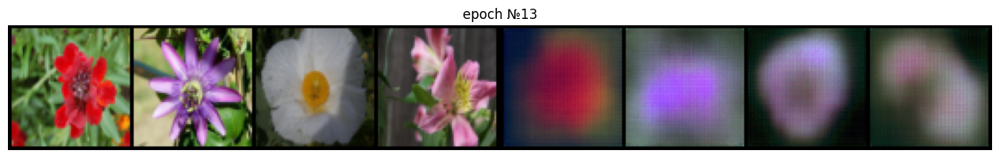

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[14/100], Loss: 0.097


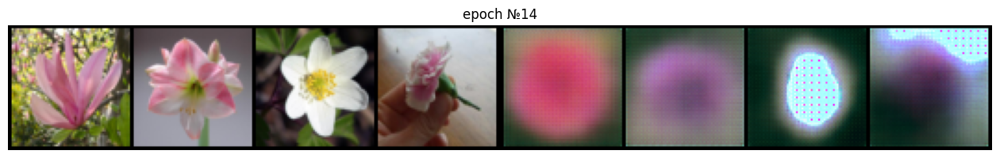

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[15/100], Loss: 0.100


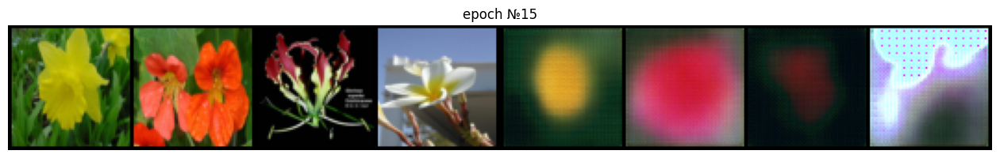

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[16/100], Loss: 0.103


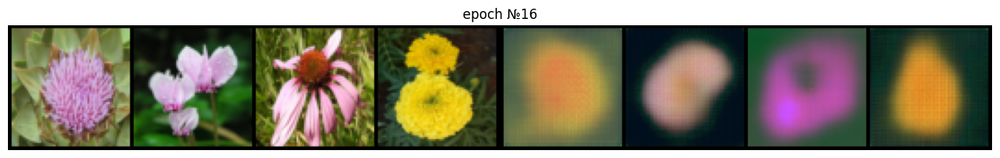

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[17/100], Loss: 0.105


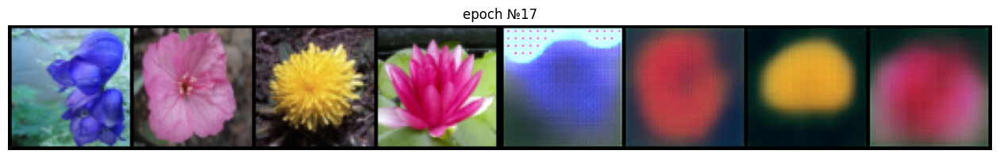

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[18/100], Loss: 0.108


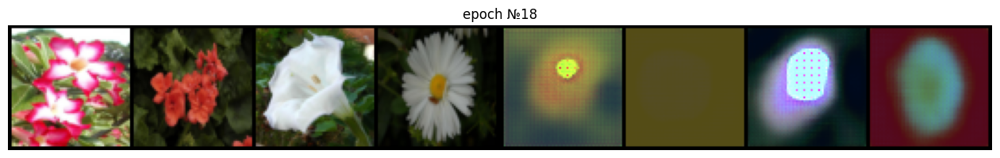

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[19/100], Loss: 0.110


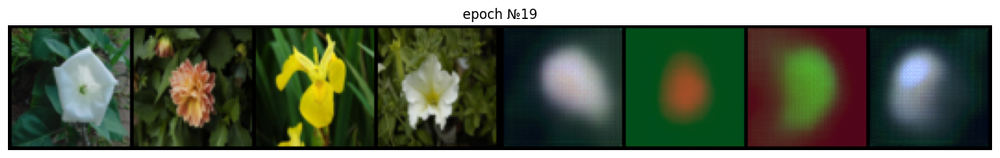

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[20/100], Loss: 0.112


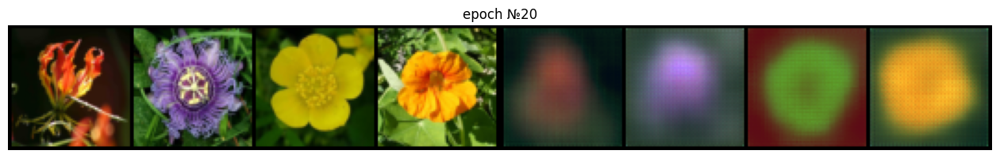

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[21/100], Loss: 0.114


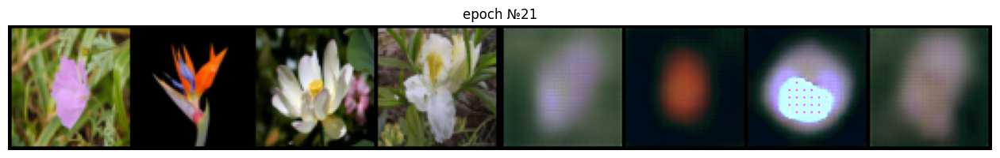

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[22/100], Loss: 0.116


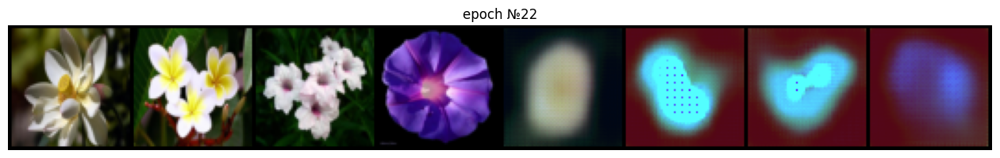

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[23/100], Loss: 0.118


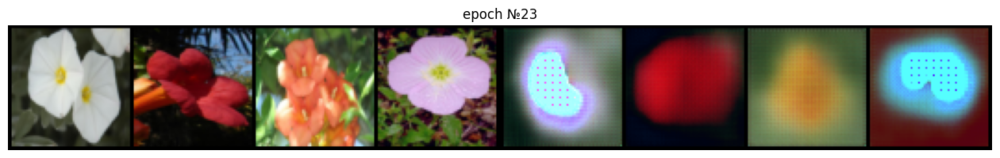

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[24/100], Loss: 0.119


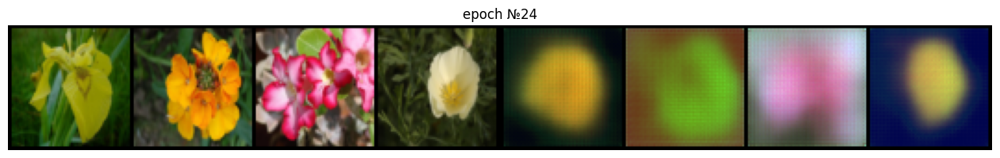

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[25/100], Loss: 0.120


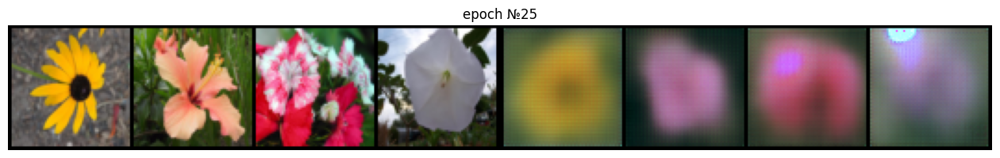

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[26/100], Loss: 0.121


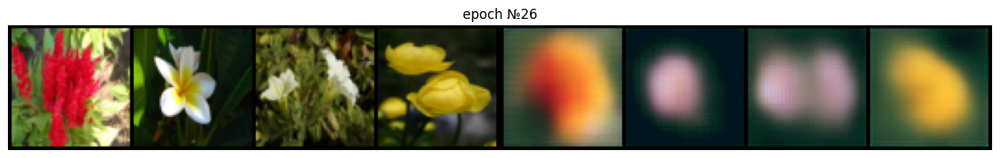

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[27/100], Loss: 0.122


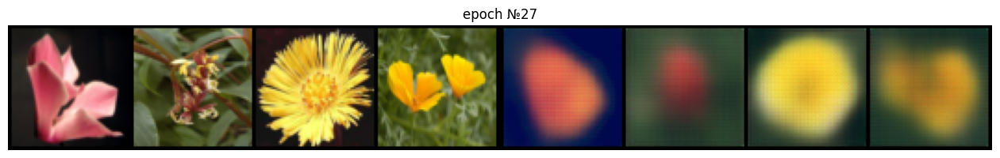

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[28/100], Loss: 0.122


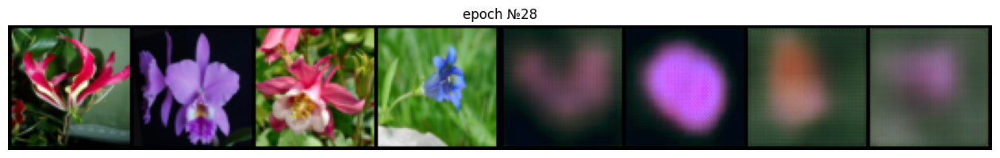

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[29/100], Loss: 0.123


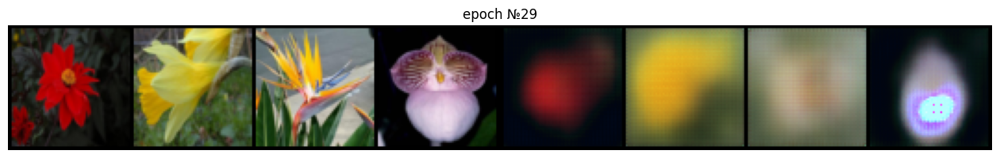

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[30/100], Loss: 0.123


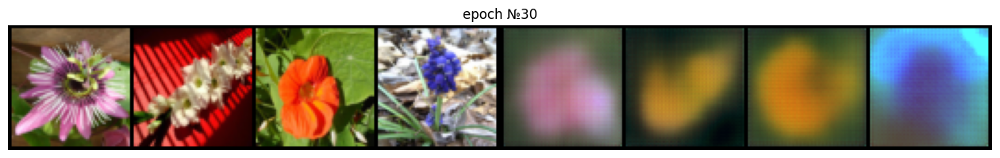

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[31/100], Loss: 0.123


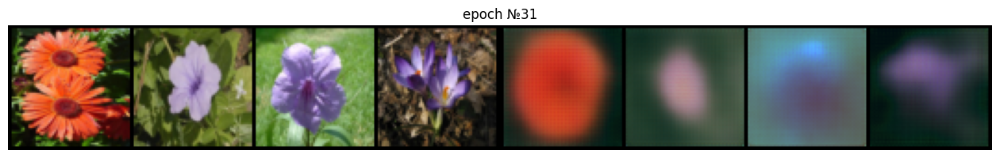

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[32/100], Loss: 0.122


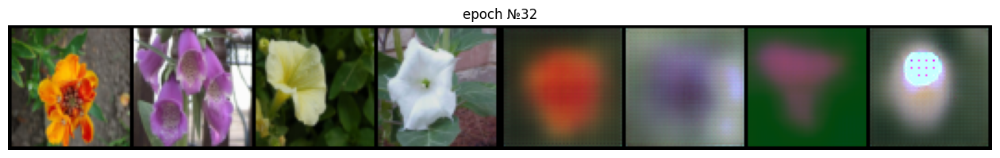

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[33/100], Loss: 0.122


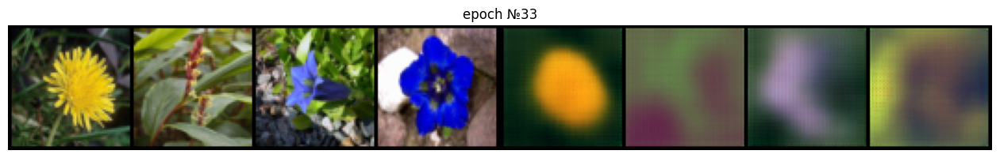

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[34/100], Loss: 0.121


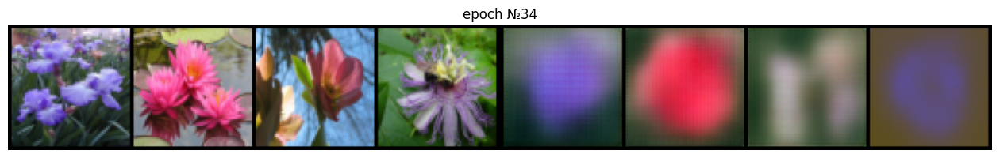

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[35/100], Loss: 0.120


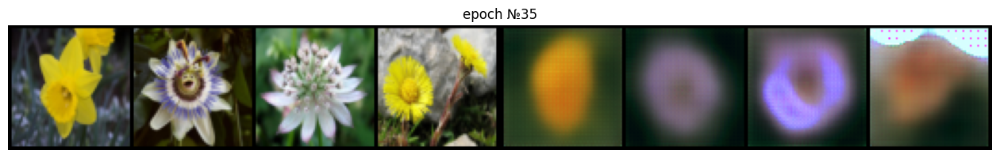

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[36/100], Loss: 0.119


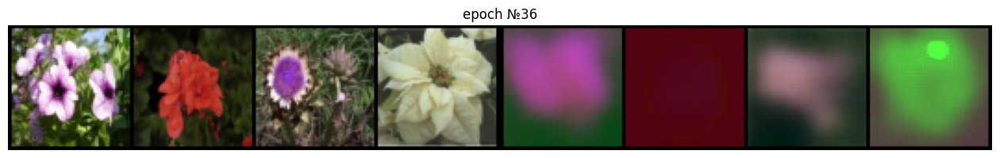

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[37/100], Loss: 0.117


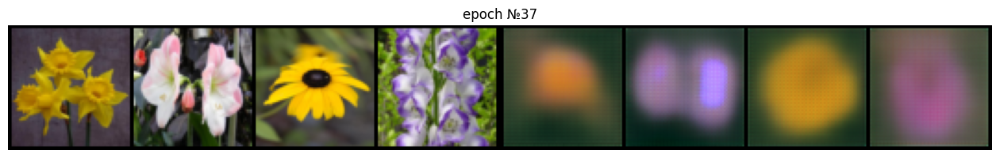

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[38/100], Loss: 0.117


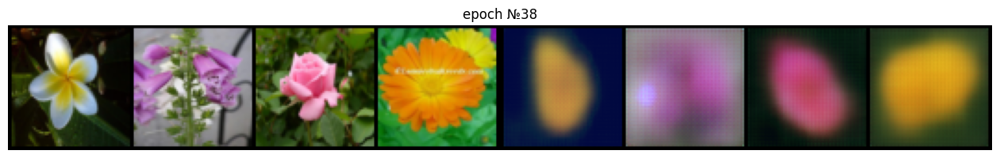

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[39/100], Loss: 0.115


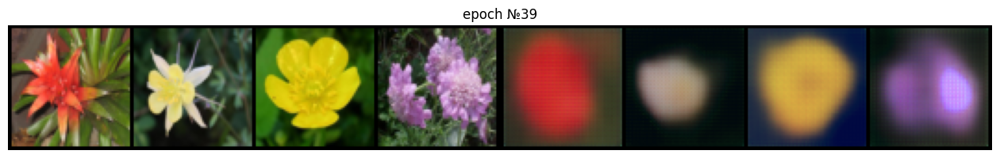

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[40/100], Loss: 0.113


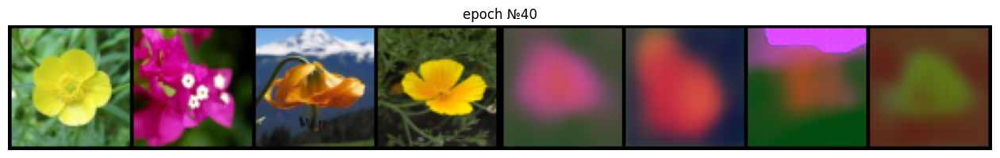

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[41/100], Loss: 0.112


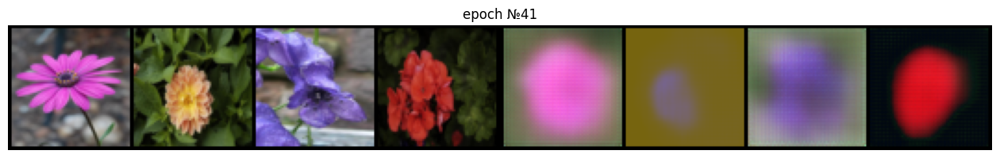

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[42/100], Loss: 0.109


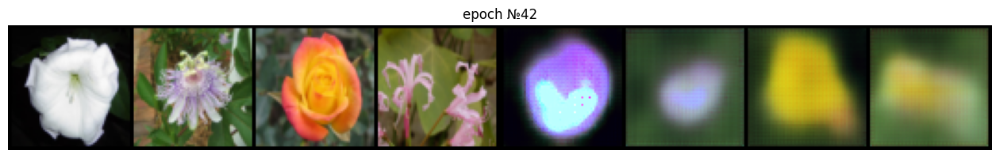

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[43/100], Loss: 0.108


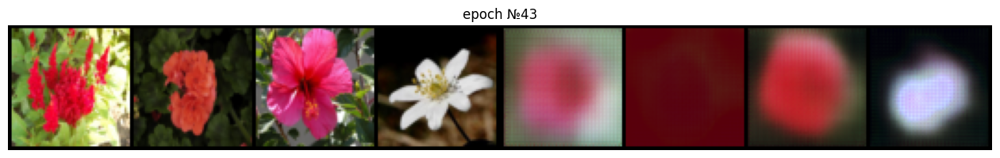

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[44/100], Loss: 0.106


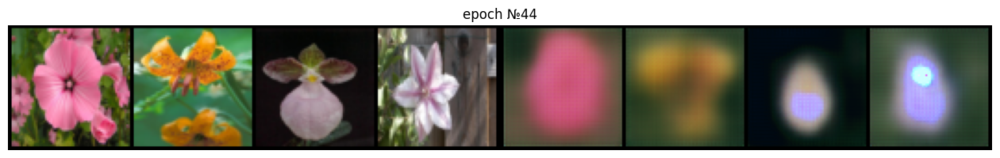

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[45/100], Loss: 0.104


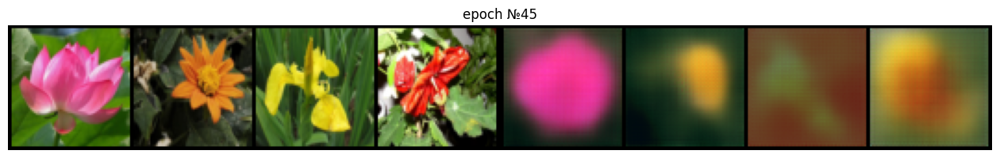

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[46/100], Loss: 0.102


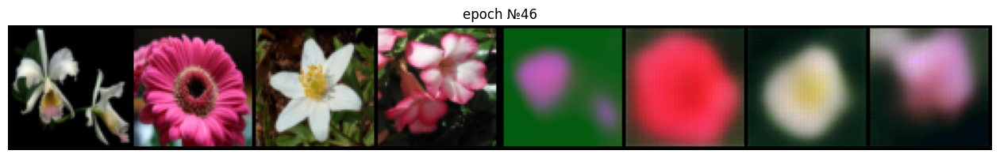

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[47/100], Loss: 0.100


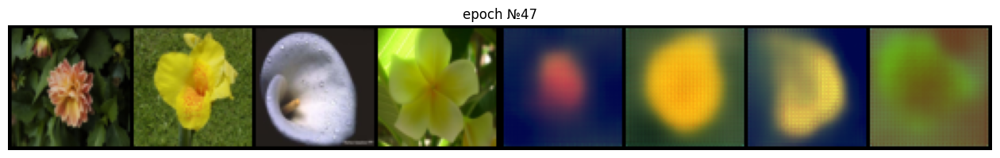

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[48/100], Loss: 0.098


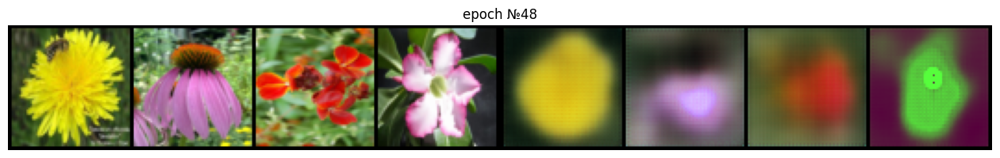

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[49/100], Loss: 0.095


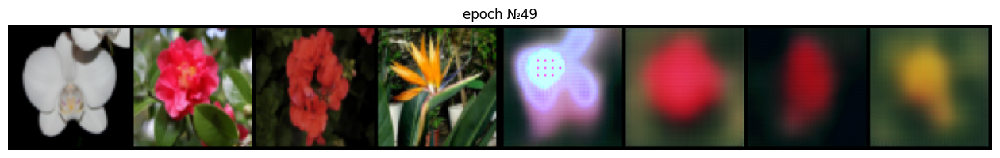

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[50/100], Loss: 0.093


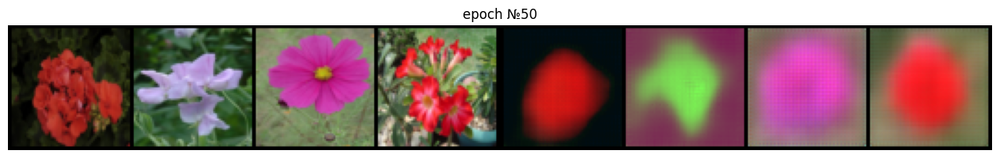

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[51/100], Loss: 0.090


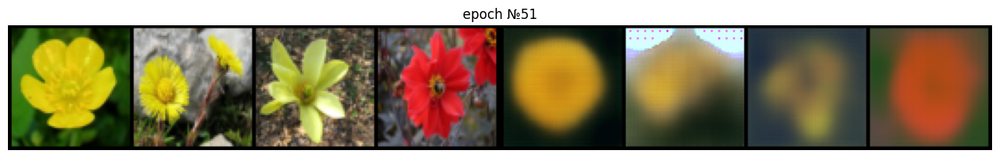

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[52/100], Loss: 0.087


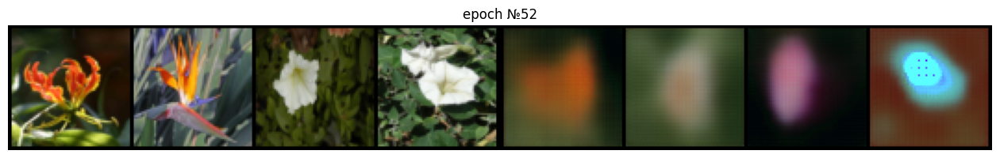

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[53/100], Loss: 0.085


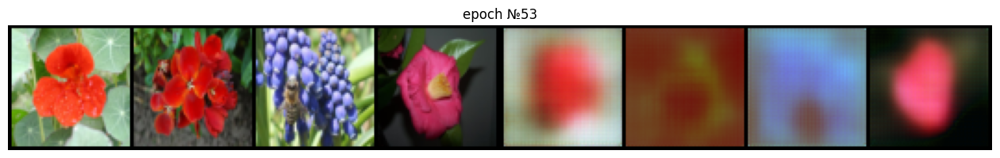

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[54/100], Loss: 0.082


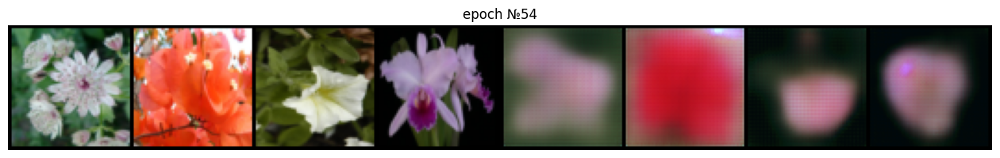

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[55/100], Loss: 0.080


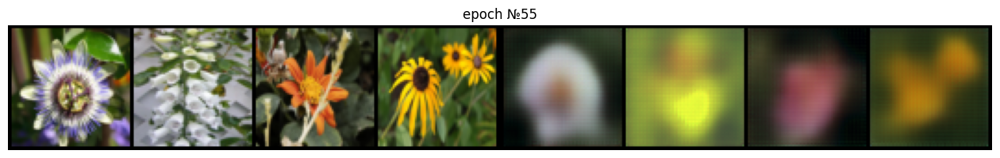

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[56/100], Loss: 0.078


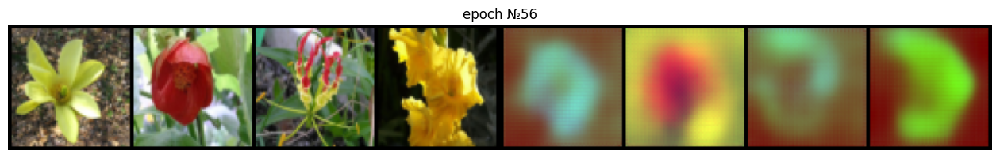

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[57/100], Loss: 0.076


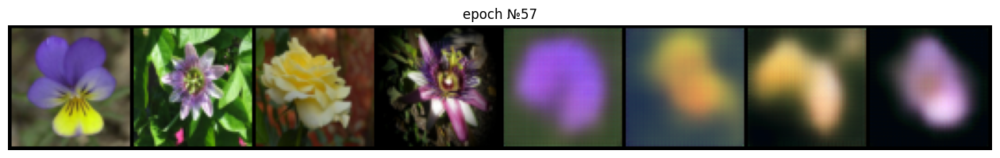

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[58/100], Loss: 0.074


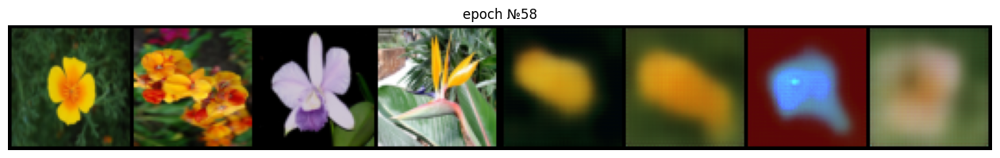

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[59/100], Loss: 0.072


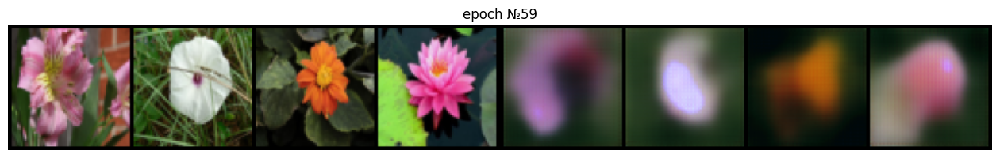

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[60/100], Loss: 0.070


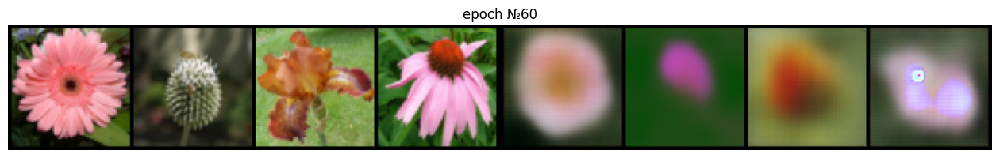

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[61/100], Loss: 0.069


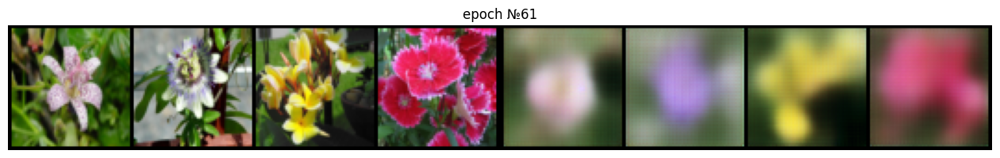

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[62/100], Loss: 0.067


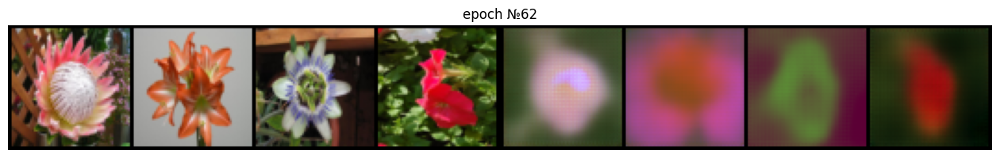

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[63/100], Loss: 0.066


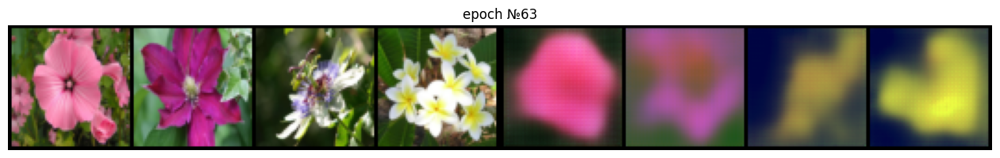

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[64/100], Loss: 0.065


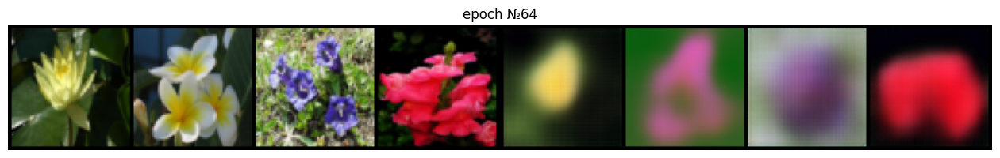

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[65/100], Loss: 0.064


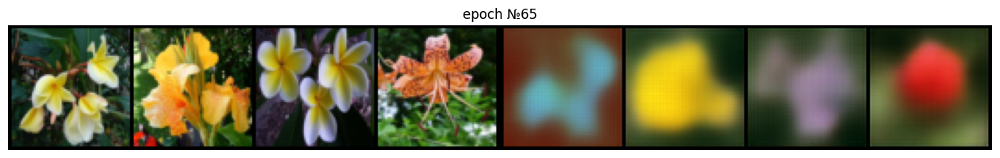

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[66/100], Loss: 0.062


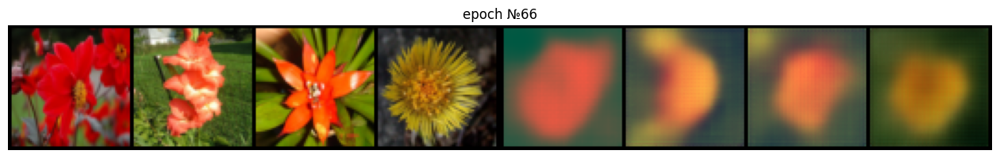

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[67/100], Loss: 0.061


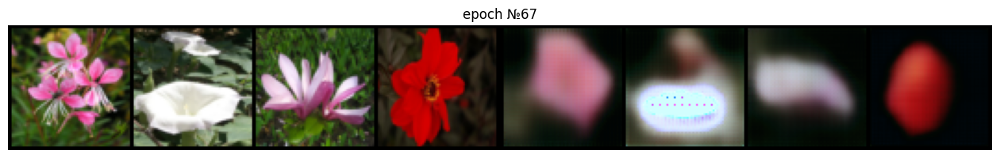

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[68/100], Loss: 0.060


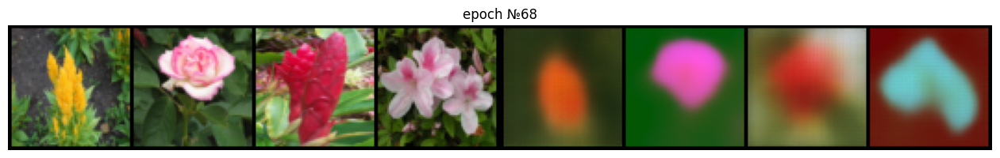

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[69/100], Loss: 0.059


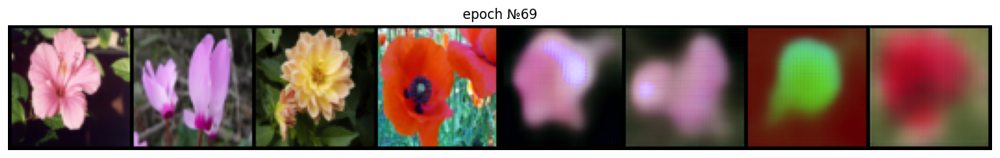

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[70/100], Loss: 0.058


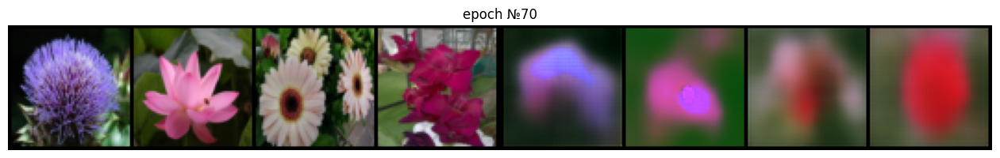

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[71/100], Loss: 0.057


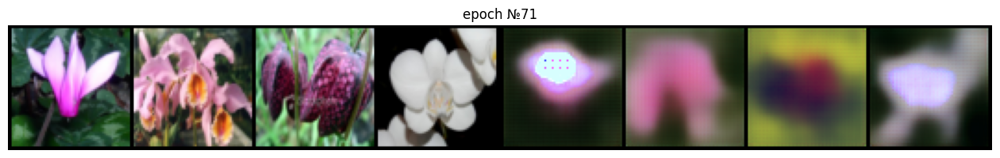

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[72/100], Loss: 0.056


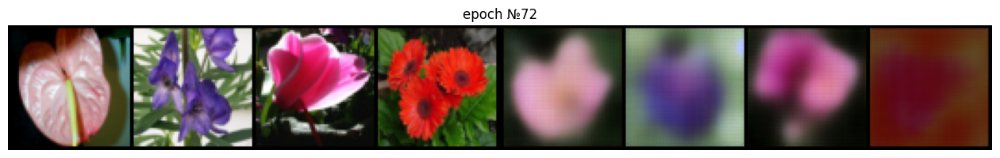

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[73/100], Loss: 0.055


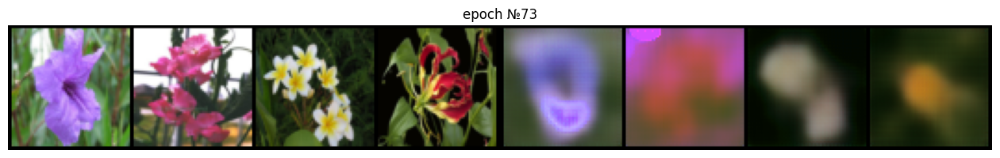

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[74/100], Loss: 0.055


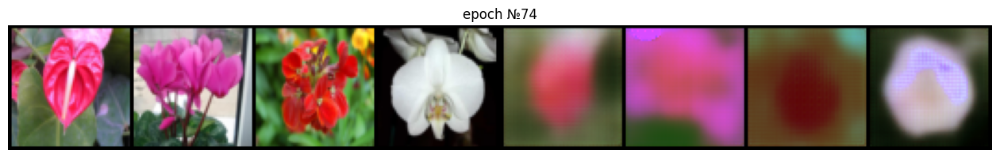

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[75/100], Loss: 0.054


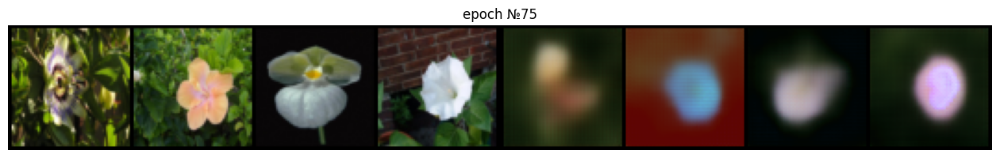

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[76/100], Loss: 0.053


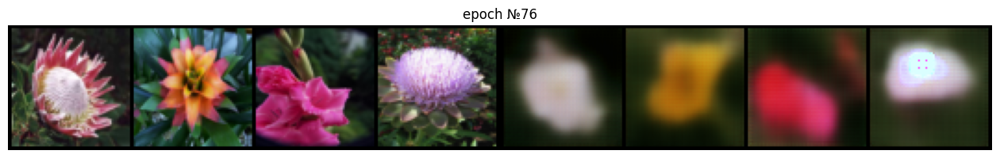

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[77/100], Loss: 0.053


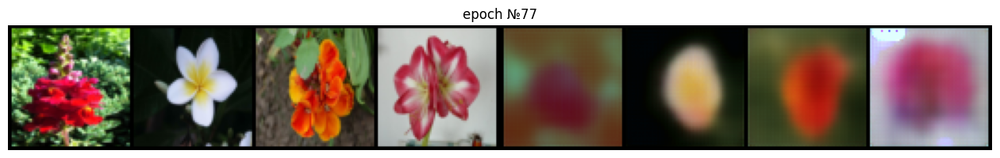

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[78/100], Loss: 0.053


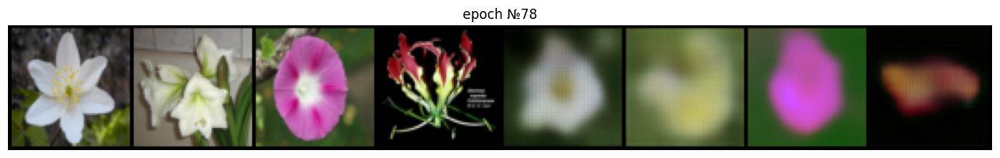

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[79/100], Loss: 0.052


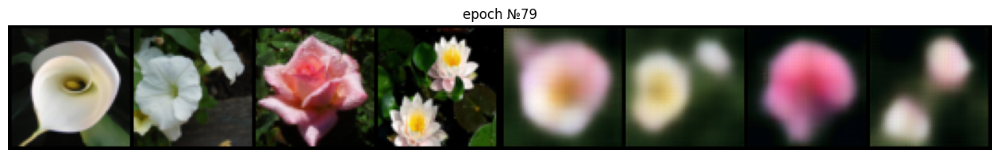

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[80/100], Loss: 0.051


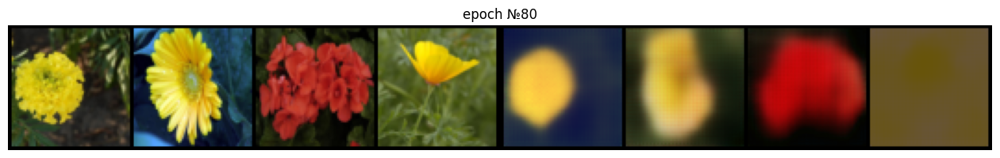

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[81/100], Loss: 0.051


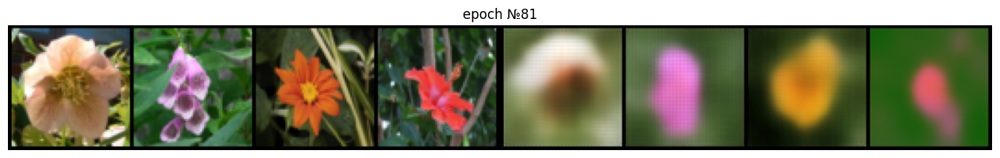

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[82/100], Loss: 0.050


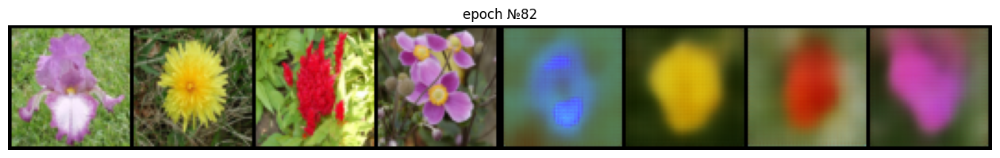

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[83/100], Loss: 0.050


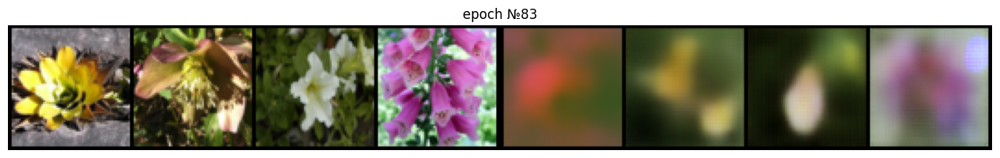

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[84/100], Loss: 0.050


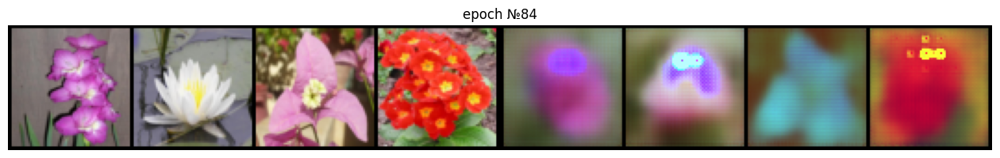

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[85/100], Loss: 0.050


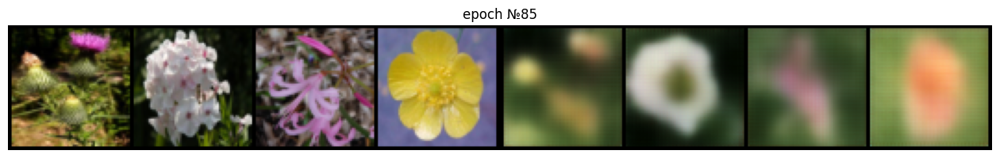

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[86/100], Loss: 0.049


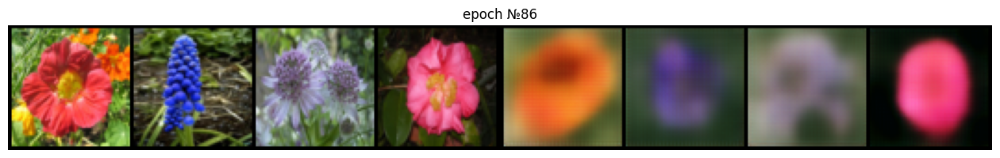

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[87/100], Loss: 0.048


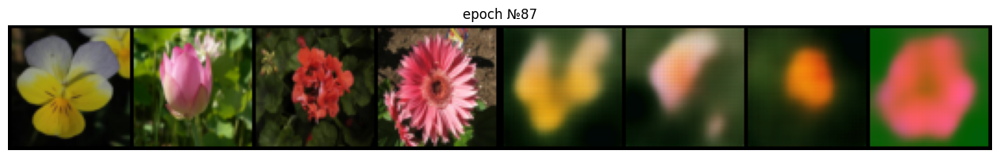

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[88/100], Loss: 0.048


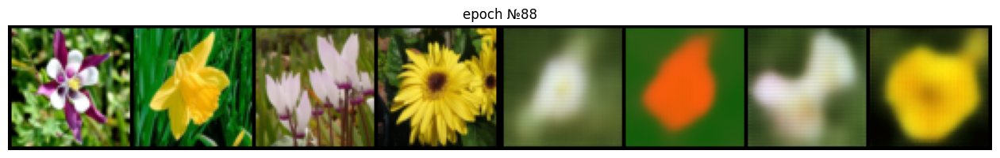

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[89/100], Loss: 0.047


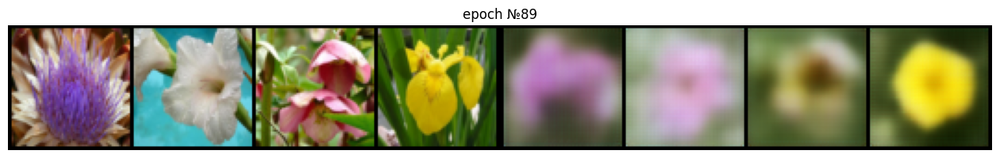

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[90/100], Loss: 0.047


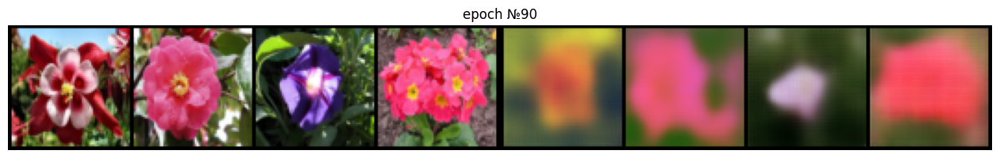

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[91/100], Loss: 0.047


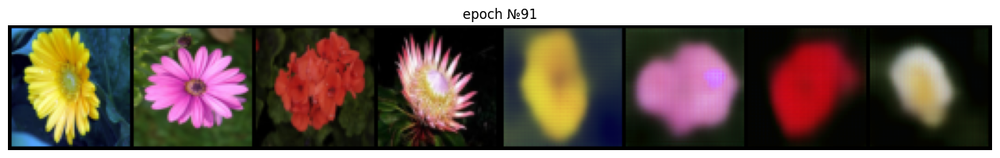

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[92/100], Loss: 0.047


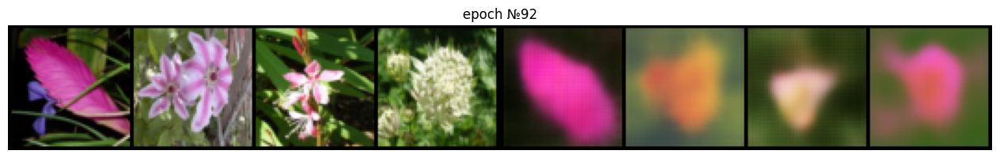

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[93/100], Loss: 0.046


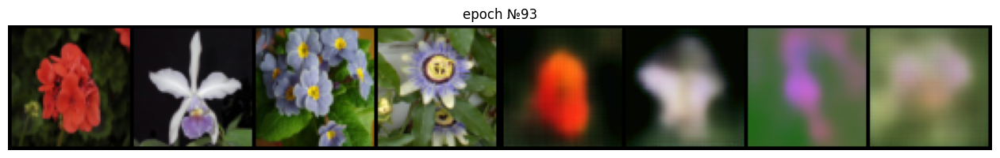

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[94/100], Loss: 0.046


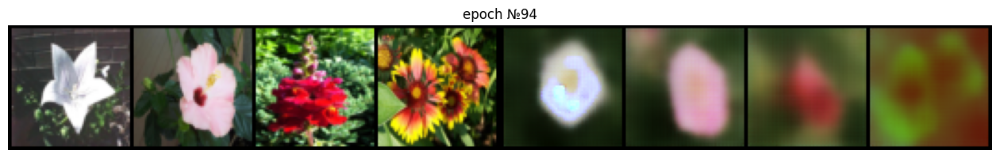

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[95/100], Loss: 0.046


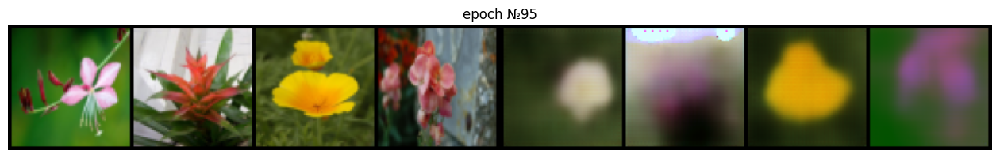

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[96/100], Loss: 0.046


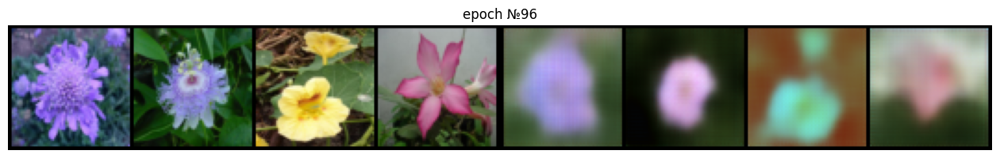

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[97/100], Loss: 0.045


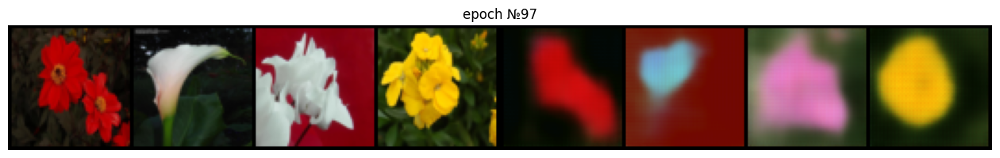

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[98/100], Loss: 0.045


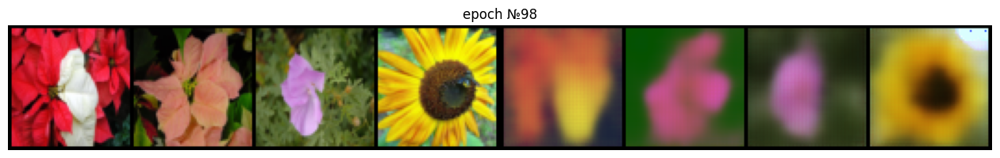

  0%|          | 0/51 [00:00<?, ?it/s]

Epoch 	[99/100], Loss: 0.045


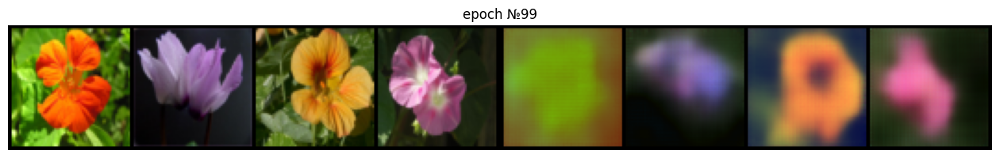

In [82]:
losses = []

for epoch in range(n_epochs):
    train_loss = 0

    for data in tqdm(data_loader, leave=False):
        imgs = data.to(device, non_blocking=True)

        mu_probs, logvar_probs = ae.enc(imgs, tau=tau(epoch, n_epochs, 1.0, 0.2))
        mu, logvar = ae.cod(mu_probs, logvar_probs)
        rec_imgs = ae.dec(mu, logvar)
        
        loss = loss_fn(imgs, rec_imgs, mu, logvar, epoch, mu_probs, logvar_probs)
        train_loss += loss.item()
        loss.backward()
        optimizer.step()

        ae.zero_grad()


    # Callback
    train_loss /= data_loader.__len__()
    losses.append(train_loss)
    print(f"Epoch \t[{epoch}/{n_epochs}], Loss: {abs(train_loss):.3f}")
    show_rec_images(ae, epoch)


<Axes: >

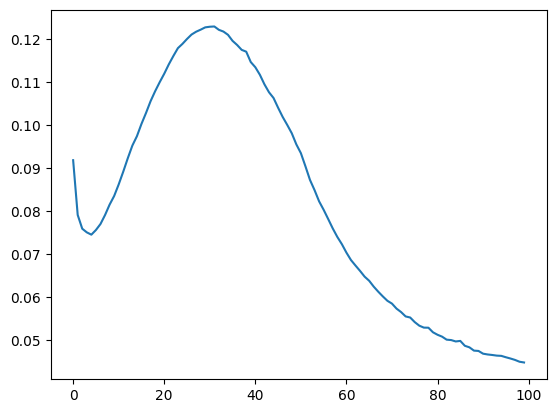

In [84]:
sns.lineplot(losses)

 **Вывод сгенерированных картинок**

In [85]:
def save_model(model, name):
    state_dict = model.state_dict()
    torch.save(state_dict, '/kaggle/working/' + name)

def load_model(model, name):
    state_dict = torch.load('/kaggle/input/models/semwin2008/vq-vae/pytorch/default/1/' + name)
    model.load_state_dict(state_dict)

In [86]:
save_model(ae, 'ae.pth')
save_model(optimizer, 'optim.pth')

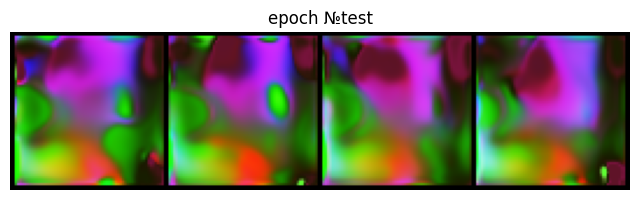

In [41]:
# load_model(ae, 'ae.pth')
# load_model(optimizer, 'optim.pth')

# show_images(ae, "test")

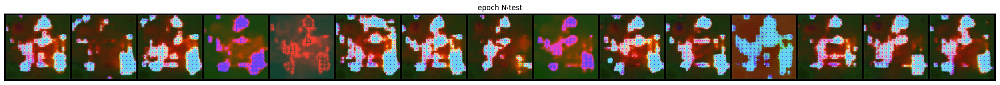

In [87]:
show_images(ae, title='test', n_images=15)

In [88]:
(codebook.mu_embed ** 2).sum(dim=-1) ** .5

tensor([5.0172, 4.3998, 0.8360, 4.7929, 5.7441, 6.4299, 4.7329, 6.5463, 6.4323,
        4.9607, 5.2915, 5.6989, 4.9960, 4.9767, 5.3862, 0.7226, 0.4637, 0.3115,
        4.4175, 0.9483, 5.9993, 5.7603, 3.2855, 3.3185, 4.2597, 0.5643, 5.5206,
        4.8704, 4.6653, 4.7253, 6.6130, 4.1556, 0.3497, 5.5345, 5.2766, 6.4571,
        4.0619, 0.5670, 6.6045, 4.6854, 6.2521, 4.4624, 3.5561, 5.6093, 5.7548,
        5.6200, 5.4909, 6.4270, 5.6819, 5.3295, 3.9203, 5.6661, 4.4819, 5.4746,
        5.5827, 4.5862, 4.1097, 0.6628, 5.5400, 5.4236, 5.3630, 5.9173, 4.0794,
        6.0021, 5.7454, 0.3043, 1.8499, 4.9028, 5.4558, 5.6479, 1.2870, 0.4999,
        3.2595, 4.9427, 6.8668, 6.8154, 5.7342, 4.7781, 5.5797, 5.1987, 5.8168,
        5.1027, 5.7959, 6.5927, 6.0614, 5.1744, 5.8682, 5.0363, 4.9789, 4.4725,
        4.5717, 0.6005, 2.0288, 4.4286, 4.8800, 4.9290, 5.8754, 5.5920, 1.3834,
        6.6114, 5.8655, 5.5680, 5.9514, 4.5702, 5.0578, 6.8820, 4.8696, 5.1987,
        4.4872, 4.5427, 5.6378, 4.6826, 

In [89]:
gen_dataset = []

for imgs in tqdm(data_loader):
    imgs = imgs.to(device)

    mu_probs, logvar_probs = ae.enc(imgs, tau=1)
    mu_tokens = mu_probs.argmax(dim=-1)
    logvar_tokens = logvar_probs.argmax(dim=-1)

    gen_dataset.append((mu_tokens, logvar_tokens))

gen_dataset = torch.cat([torch.cat([mu.unsqueeze(1), logvar.unsqueeze(1)], dim=1) for mu, logvar in gen_dataset], dim=0)

gen_train, gen_test = train_test_split(gen_dataset, test_size=0.2)

  0%|          | 0/51 [00:00<?, ?it/s]

In [90]:
gen_train.size()

torch.Size([5222, 2, 16])

<Axes: ylabel='Count'>

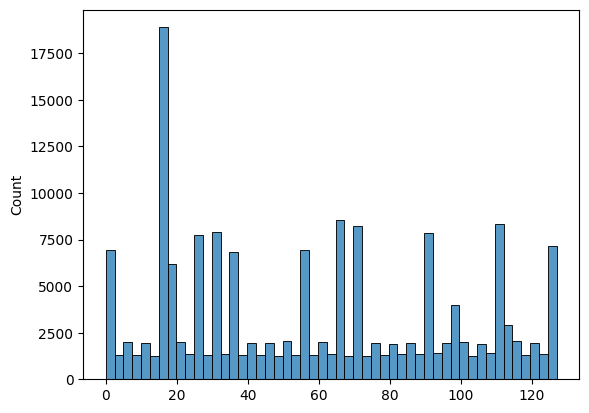

In [91]:
sns.histplot(torch.flatten(gen_train.detach().cpu()), label='token_usage')

<Axes: ylabel='Count'>

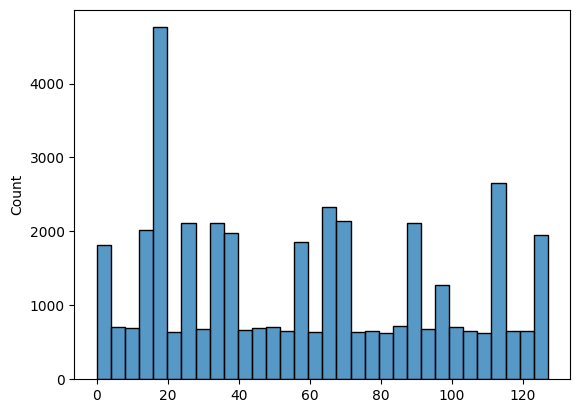

In [92]:
sns.histplot(torch.flatten(gen_test.detach().cpu()), label='token_usage')

In [93]:
class OneSeqGen(nn.Module):
    def __init__(self, codebook_size, sequence_len, embedding_dim, hidden_dim=1024):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.rnn = nn.RNN(embedding_dim, hidden_dim)
        self.ff = LinearBlock(hidden_dim, codebook_size)

    def forward(self, seq_mu, h_cur_m=None):
        if not h_cur_m:
            h_cur_m = torch.zeros(1, self.hidden_dim, device=device)
        h_m = self.rnn(seq_mu, h_cur_m)[0]
        h_m = self.ff(h_m)

        return h_m

class Generator(nn.Module):
    def __init__(self, codebook_size, sequence_len, hidden_dim):
        super().__init__()
        self.mu = OneSeqGen(codebook_size, sequence_len, hidden_dim)
        self.logvar = OneSeqGen(codebook_size, sequence_len, hidden_dim)

    def forward(self, seq_mu, seq_logvar, h_cur_m=None, h_cur_l=None):
        return self.mu(seq_mu, h_cur_m), self.logvar(seq_logvar, h_cur_l)

In [98]:
generator = Generator(Y, X*X, hidden_dim).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(generator.parameters(), lr=3e-4)

In [99]:
def seq_to_embed(seq_mu, seq_logvar):
    mu_embed = torch.zeros(len(seq_mu), hidden_dim, device=device)
    for i, token in enumerate(seq_mu):
        token = token.to(device)
        if token < Y:
            mu_embed[i] = codebook.mu_embed[token]
    logvar_embed = torch.zeros(len(seq_logvar), hidden_dim)
    for i, token in enumerate(seq_logvar):
        token = token.to(device)
        if token < Y:
            logvar_embed[i] = codebook.logvar_embed[token]
    return mu_embed, logvar_embed

In [100]:
def validate(model, data):
    model.eval()
    running_loss = 0
    for seq_mu, seq_logvar in tqdm(data, leave=False):
        seq_mu = torch.cat([torch.tensor([Y], device=device), seq_mu])
        seq_logvar = torch.cat([torch.tensor([Y], device=device), seq_logvar])
        seq_mu = seq_mu.to(device) # tokens
        seq_mu = seq_mu.to(device) # tokens
        seq_logvar = seq_logvar.to(device) # tokens
        
        # СДВИГ: вход [0..T-1], цель [1..T]
        input_mu = seq_mu[:-1]
        target_mu = seq_mu[1:]
        input_logvar = seq_logvar[:-1]
        target_logvar = seq_logvar[1:]
        
        mu_embed, logvar_embed = seq_to_embed(input_mu, input_logvar)
        mu_embed = mu_embed.to(device)
        logvar_embed = logvar_embed.to(device)
        
        h_m, h_l = generator(mu_embed, logvar_embed)
        loss = criterion(h_m, target_mu) + criterion(h_l, target_logvar)
        
        running_loss += loss.item()
        
    running_loss /= len(data)
    model.train()
    return running_loss

In [101]:
n_epochs = 20

gen_train_losses = []
gen_valid_losses = []

generator.train()

for epoch in range(n_epochs):
    train_loss = 0
    for seq_mu, seq_logvar in tqdm(gen_train, leave=False):
        seq_mu = torch.cat([torch.tensor([Y], device=device), seq_mu])
        seq_logvar = torch.cat([torch.tensor([Y], device=device), seq_logvar])
        seq_mu = seq_mu.to(device) # tokens
        seq_logvar = seq_logvar.to(device) # tokens
        
        # СДВИГ: вход [0..T-1], цель [1..T]
        input_mu = seq_mu[:-1]
        target_mu = seq_mu[1:]
        input_logvar = seq_logvar[:-1]
        target_logvar = seq_logvar[1:]

        mu_embed, logvar_embed = seq_to_embed(input_mu, input_logvar)
        mu_embed = mu_embed.to(device)
        logvar_embed = logvar_embed.to(device)
        
        h_m, h_l = generator(mu_embed, logvar_embed)
        loss = criterion(h_m, target_mu) + criterion(h_l, target_logvar)
        
        train_loss += loss.item()
        
        generator.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(gen_train)
    gen_train_losses.append(train_loss)
    valid_loss = validate(generator, gen_test)
    gen_valid_losses.append(valid_loss)
    
    print(f'Epoch [{epoch}/{n_epochs}] Train Loss {train_loss:.4f} Valid Loss {valid_loss:.4f}')

print('!! Training completed !!')

  0%|          | 0/5222 [00:00<?, ?it/s]

  0%|          | 0/1306 [00:00<?, ?it/s]

Epoch [0/20] Train Loss 8.5641 Valid Loss 8.7241


  0%|          | 0/5222 [00:00<?, ?it/s]

  0%|          | 0/1306 [00:00<?, ?it/s]

...

  0%|          | 0/1306 [00:00<?, ?it/s]

Epoch [18/20] Train Loss 5.1797 Valid Loss 12.5146


  0%|          | 0/5222 [00:00<?, ?it/s]

  0%|          | 0/1306 [00:00<?, ?it/s]

Epoch [19/20] Train Loss 5.1100 Valid Loss 12.6364
!! Training completed !!


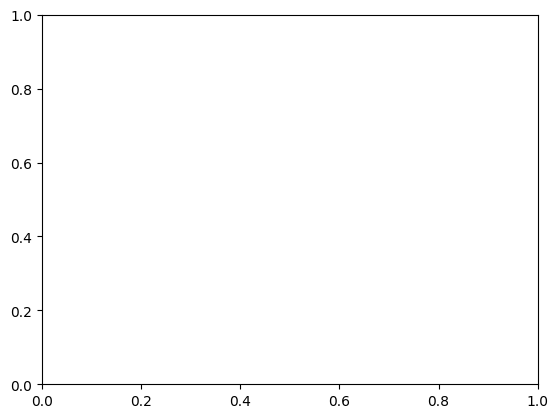

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(gen_train_losses, label='train')
sns.lineplot(gen_valid_losses, label='valid')

plt.show()

In [68]:
def generate_sequence(model, seq_len, temp=1):
    model.eval()
    
    x = torch.zeros(1, hidden_dim, device=device)
    y = torch.zeros(1, hidden_dim, device=device)
    h_m, h_l = None, None
    
    generated = []
    generated_embed = []
    
    for _ in range(seq_len):
        mu_logits, logvar_logits = model(x, y, h_m, h_l)
        mu_logits = mu_logits / temp
        logvar_logits = logvar_logits / temp
        
        mu_probs = F.softmax(mu_logits, dim=-1)
        logvar_probs = F.softmax(logvar_logits, dim=-1)
        mu_next_token = torch.multinomial(mu_probs, 1).item()
        logvar_next_token = torch.multinomial(logvar_probs, 1).item()
        generated.append((mu_next_token, logvar_next_token))
        
        x = codebook.mu_embed[mu_next_token].unsqueeze(0)
        y = codebook.logvar_embed[logvar_next_token].unsqueeze(0)
        generated_embed.append(torch.cat([x, y], dim=0).unsqueeze(0))
    
    return generated, generated_embed

In [69]:
test_seq, test_embed = generate_sequence(generator, X*X)
test_seq

[(18, 47),
 (52, 66),
 (98, 6),
 (49, 47),
 (77, 108),
 (11, 24),
 (60, 27),
 (28, 82),
 (30, 22),
 (61, 21),
 (82, 40),
 (97, 43),
 (58, 47),
 (64, 12),
 (60, 118),
 (121, 100)]

In [70]:
def generate_image():
    decoder.eval()
    seq_embed = generate_sequence(generator, X*X)[1]
    embed = torch.cat(seq_embed, dim=0)
    mu = embed[:, 0]
    logvar = embed[:, 0]
    img = decoder(mu, logvar)
    return img

In [71]:
def show_generated_images(n_images=6, title='test'):
    images = torch.cat([generate_image() for i in range(n_images)])
    
    grid = vutils.make_grid(images.detach().cpu(), nrow=len(images), padding=2, normalize=True)

    plt.figure(figsize=(len(images) * 2, 3))
    plt.axis("off")
    plt.title(f"epoch №{title}")

    # make_grid возвращает (C, H, W), поэтому всё равно нужно permute для imshow
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.show()

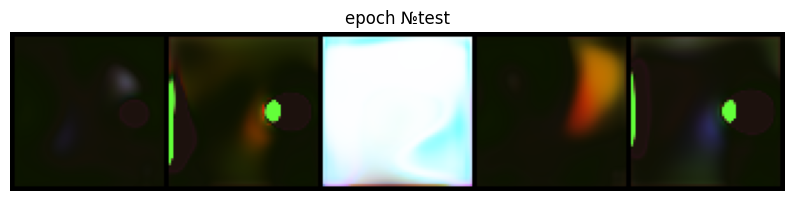

In [56]:
show_generated_images(5)